# Generative admixture correction on CosMx NSCLC (Python)

The generative model corrects admixture by decomposing each cell's counts
into the cell's own expression, contamination from each neighboring cell
type, ambient background, and expression the cell switched on in response
to its neighborhood; the contamination and ambient shares are removed,
the induced expression retained (`docs/generative.md`). This notebook runs
it on the CosMx NSCLC dataset with the Python bindings — the same analysis
as `nsclc_generative.Rmd` — and characterizes both sides of the
separation: the pattern of admixture between cell types, and the induced
programs the correction preserves. This CosMx export carries no
nucleus-overlap flag, so the model uses whole-cell rather than
cytoplasmic source profiles.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

from celladmix import CellAdmix

# the figure helpers of the generative-model documentation, kept with the analysis
sys.path.insert(0, str(Path("../../analysis/generative_model/tools").resolve()))
from generative_plots import (generative_exposure, generative_plot_composition,
    generative_plot_composition_map, generative_plot_gene_contrast,
    generative_induced_changes, generative_plot_volcano_pair)

The Python bindings read Xenium and Atera output directly. This dataset
is a CosMx molecule table, which the R package reads (`format =
"tabular"`), so the notebook attaches to the input store that
`nsclc_generative.Rmd` builds in `out/` and adds the coarse cell
annotation:

In [2]:
cell_meta = pd.read_csv(Path("prepared") / "cell_metadata_all.csv.gz")
annotation = pd.Series(cell_meta["cell_type_coarse"].to_numpy(),
                       index=cell_meta["cell"].astype(str))
ds = CellAdmix.attach_existing("out", annotation=annotation, num_threads=8)
ds

CellAdmix(format='tabular', source='/home/pkharchenko/cellAdmix/cellAdmix-core/examples/cosmx_nsclc_giotto/prepared/molecules_all.csv.gz', output_dir='out', annotation=6 labels, num_threads=8)

## The admixture pattern between cell types

The audit estimates, for every ordered pair of cell types, how many
molecules of the source type are admixed into cells of the target type,
from the rise of source-marker content with the number of source-type
neighbors. It is computed straight from the dataset — counts, cell
positions and the annotation; no factorization is involved.

Excluded 72 likely induced genes from marker panels (exposure-linked excess far above the source-profile expectation): MT1X, HLA-B, HSP90AA1, MT2A, GPX3, DUSP5, HSPA1A, MIF


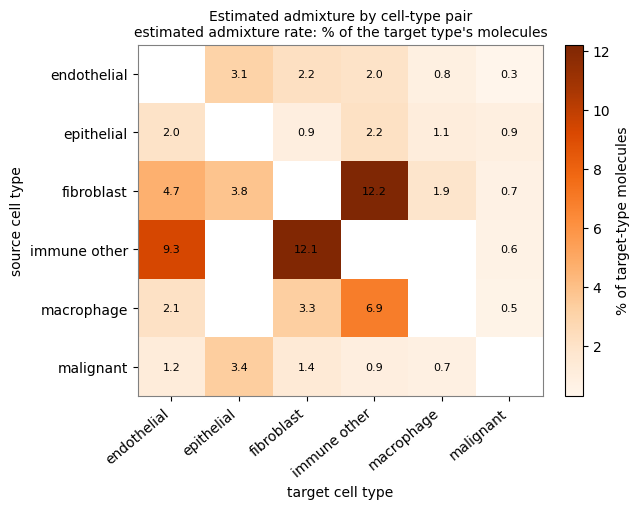

In [3]:
audit = ds.audit_admixture()
fig, ax = plt.subplots(figsize=(6.5, 5.2))
audit.plot_map(ax=ax)
fig.tight_layout()

In [4]:
pairs = audit.pairs(detected_only=True)
pairs.sort_values("rate", ascending=False)[
    ["source", "target", "admixed_molecules", "rate"]].head(8)

,source,target,admixed_molecules,rate
12,fibroblast,immune other,1325145,0.122028
16,immune other,fibroblast,474902,0.120764
15,immune other,endothelial,214239,0.093161
21,macrophage,immune other,747404,0.068826
10,fibroblast,endothelial,107226,0.046627
11,fibroblast,epithelial,58450,0.038152
24,malignant,epithelial,51489,0.033609
20,macrophage,fibroblast,130021,0.033063


Aggregated over targets, the estimated admixed molecules by source type
— dominated by the tumor and myeloid compartments:

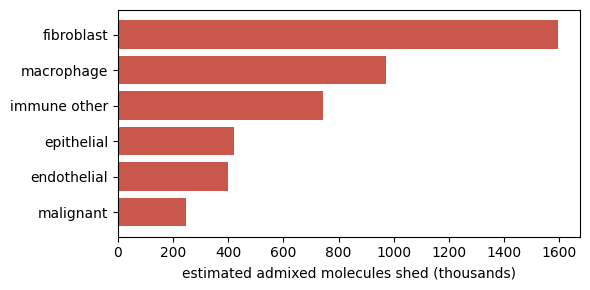

In [5]:
by_source = pairs.groupby("source")["admixed_molecules"].sum().sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(by_source.index, by_source / 1e3, color="#c0392b", alpha=0.85)
ax.set_xlabel("estimated admixed molecules shed (thousands)")
fig.tight_layout()

## Correcting with the generative model

The model is fitted on the audit's detected pairs. The NMF fit enters
only to initialize the model's expression programs — the recommended
configuration — and the correction derives from the fitted model. The
rank-8 NMF fit stored with the example is reused here; `ds.fit(rank=8)`
computes it afresh.

In [6]:
nmf_fit = ds.load_fit("fit_manual_rank8_ls_nmf")
model = audit.fit_generative(init=nmf_fit, num_threads=8, verbose=False)
correction = model.correct()
model.pairs.sort_values("removed_molecules_expected", ascending=False).head(6)

,source,target,estimated_dose_molecules,removed_molecules_expected,induced_molecules,mean_dose_exposed,prior_unexposed_molecules,cross_attributed_molecules
15,fibroblast,immune other,1.188533e+06,1.124037e+06,0.000000,0.137811,124343.008317,64348.587701
16,macrophage,immune other,6.318994e+05,6.959782e+05,158536.638105,0.100956,214420.209255,101818.957963
10,immune other,fibroblast,3.469723e+05,3.527509e+05,5127.266728,0.090067,0.000000,31655.781104
13,endothelial,immune other,1.773691e+05,1.781168e+05,66398.062320,0.032027,8566.885129,11282.534946
14,epithelial,immune other,1.566128e+05,1.608619e+05,7253.425733,0.046907,29932.739580,9276.344804
2,immune other,endothelial,1.609356e+05,1.607177e+05,0.000000,0.071074,58.758782,15378.230682


The model's central quantity is the per-cell contamination fraction: how
much of each cell's content is admixed from each source. Its dependence on
the number of source neighbors, for the pair with the most admixed
molecules, and the same fractions drawn in space:

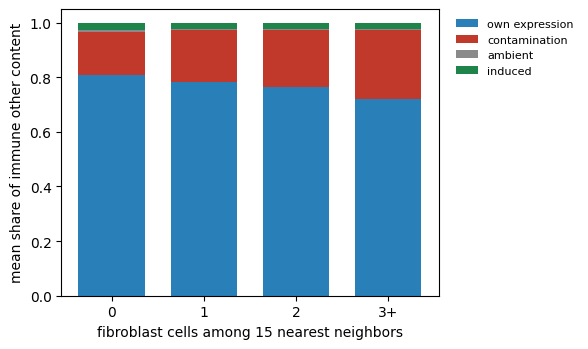

In [7]:
top = pairs.sort_values("admixed_molecules", ascending=False).iloc[0]
cells_xy = ds.cells()
expo = generative_exposure(cells_xy, ds.annotation, top["source"])
fig, ax = plt.subplots(figsize=(6, 3.6))
generative_plot_composition(model, top["target"], expo,
    f"{top['source']} cells among 15 nearest neighbors", ax=ax)
fig.tight_layout()

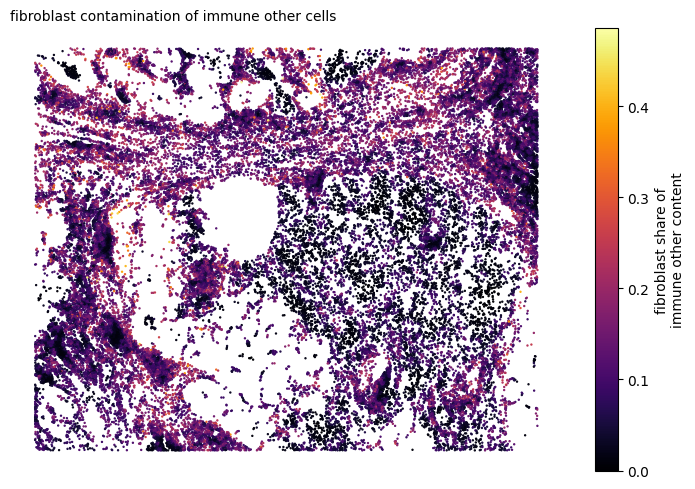

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
generative_plot_composition_map(model, top["source"], top["target"], cells_xy, cap=0.5, ax=ax)
fig.tight_layout()

## The induction pattern

The model retains genes whose exposure-linked excess exceeds what
admixture from the source can deliver — expression the target cells
switched on themselves. On this tissue the retained set reads as the
stress, immediate-early and chemokine programs of cells at tissue
interfaces:

In [9]:
induced = model.induced
induced.sort_values("excess", ascending=False)[
    ["source", "target", "gene", "excess", "fold", "z"]].head(10)

,source,target,gene,excess,fold,z
35,endothelial,immune other,HSPA1A,10822.071196,4.115143,17.490986
36,endothelial,immune other,HSPA1B,9197.785643,4.069398,16.710038
42,macrophage,immune other,GLUL,7484.990923,2.531707,9.664492
45,macrophage,immune other,SRGN,7152.530886,5.427592,20.806496
40,macrophage,immune other,NPPC,6637.024225,2.434147,8.265181
83,macrophage,malignant,DUSP5,5885.255187,7.805129,24.148237
19,endothelial,fibroblast,COL4A2,5441.594846,4.089366,15.346591
4,macrophage,endothelial,DUSP5,5257.256058,6.922909,16.729099
27,macrophage,fibroblast,DUSP5,5209.541879,3.296008,10.064316
15,endothelial,fibroblast,COL4A1,4278.496700,3.739442,14.421808


The contrast between an admixed and an induced gene, for the pair with
the strongest induced signal — the observed rise of the admixed gene is
flattened to the unexposed level, while the induced gene keeps its
gradient:

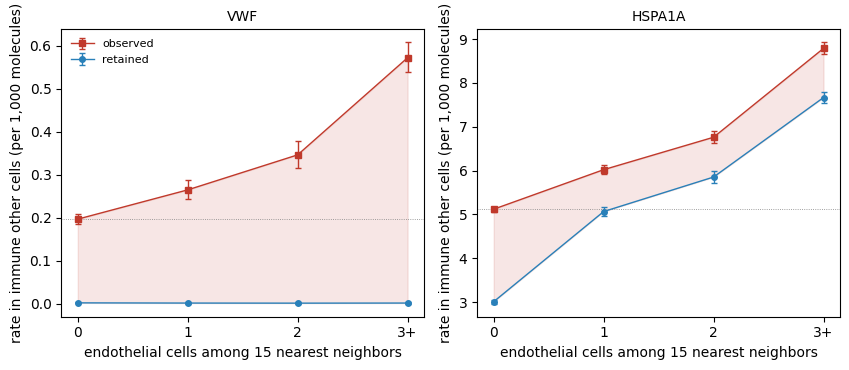

In [10]:
ind_top = induced.sort_values("excess", ascending=False).iloc[0]
mk = audit.markers(ind_top["source"], ind_top["target"])
admixed_gene = next(g for g in mk["pool"] if g not in set(induced["gene"]))

before, genes, cell_ids = ds.counts()
after, _, _ = correction.counts()
t_cells = model.composition(ind_top["source"], ind_top["target"])["cell_id"].tolist()
expo_t = generative_exposure(cells_xy, ds.annotation, ind_top["source"])
axes = generative_plot_gene_contrast(before, after, genes, cell_ids, t_cells, expo_t,
    [admixed_gene, ind_top["gene"]],
    f"{ind_top['source']} cells among 15 nearest neighbors",
    f"rate in {ind_top['target']} cells (per 1,000 molecules)")
axes[0].figure.tight_layout()

Beyond the genes the model retains by its own screen, the corrected
counts support the general question of which genes — of any ownership,
in either direction — change in the target cells with the source's
proximity, tested jointly across all sources (`docs/generative.md`,
Figure 5). The same test on the observed counts shows what the correction
changes. A change is reported at six standard errors (dotted line) and
at least a 4% change per neighboring cell; reported genes are colored by
direction, and genes not reported are small grey dots. Filled circles
are genes with essentially none of their content removed as admixture
and no meaningful share of the source's admixture profile; filled
squares are genes partly removed as admixture, whose change after
correction rests on the model's estimate of the admixed part. On the
left (observed counts), hollow circles are associations reported before
correction but not after: the admixture accounts for them. The most
significant reported genes are named in each panel.

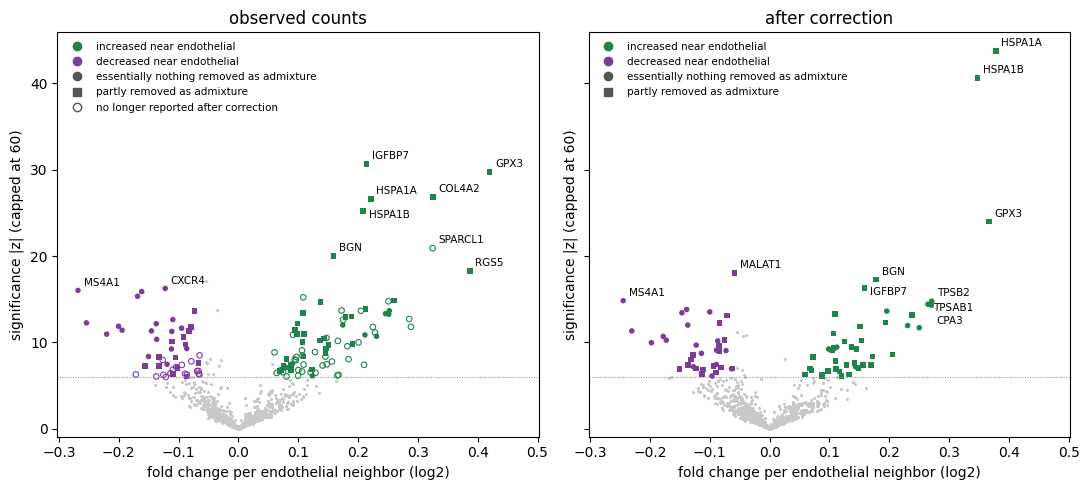

In [11]:
changes = generative_induced_changes(before, after, genes, cell_ids, model, cells_xy,
    ds.annotation, ind_top["target"])
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
generative_plot_volcano_pair(changes, ind_top["source"], axes=axes)
fig.tight_layout()

## Verification

The correction is verified against the audit's own measurements, like any
other correction in the package.

In [12]:
report = audit.evaluate(correction)
report.summary()

{'detected_pairs': 27,
 'estimated_admixed_molecules': 4381180,
 'leakage_removed_overall': np.float64(0.9688948522749822),
 'median_pair_sensitivity': 0.99773601393869,
 'own_marker_false_removal': 0.0}

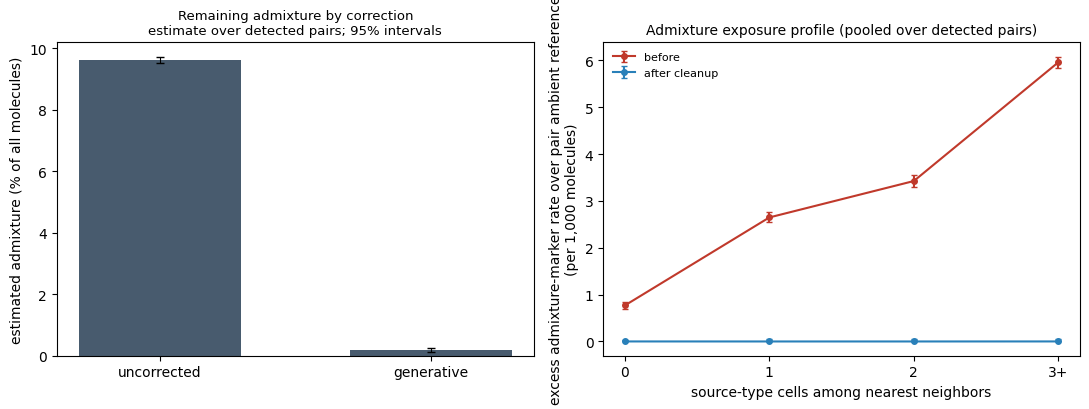

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
audit.plot_remaining({"generative": correction}, ax=axes[0])
audit.plot_exposure(correction=correction, ax=axes[1])
fig.tight_layout()

The model never removes a target type's own marker genes, and induced
expression is only recognizable when disproportionate to the source's
admixture profile — see the identifiability limit in
`docs/generative.md`.